In [73]:
import pandas as pd
import numpy as np

In [74]:
oc = pd.read_csv("../my_dataset.csv")
oc

,OPTION TYPE,STRIKE,LTP,UNDERLYING VALUE,IV,TIME TO MATURITY
0,Call,55500.0,760.00,55540.05,12.30,385
1,Call,57000.0,200.50,55540.05,12.28,385
2,Put,55500.0,739.05,55540.05,16.43,385
3,Call,58000.0,60.90,55540.05,12.25,385
4,Call,56000.0,515.00,55540.05,12.29,385
...,...,...,...,...,...,...
9096,Call,58700.0,NaN,55488.10,NaN,400
9097,Put,59800.0,NaN,55488.10,NaN,400
9098,Put,60100.0,NaN,55488.10,NaN,400
9099,Call,60300.0,NaN,55488.10,NaN,400


In [75]:
oc["LTP"].isnull().sum()

np.int64(3476)

In [76]:
oc = oc[-(oc["LTP"].isnull())]

<h3> Using Z-Score removal</h3>

<Axes: xlabel='IV', ylabel='Density'>

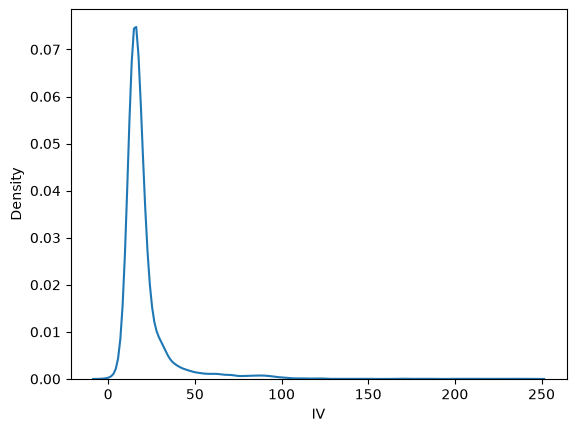

In [77]:
import seaborn as sb
sb.kdeplot(oc["IV"])

In [78]:
oc["IVzscore"] = (oc["IV"]-oc["IV"].mean())/oc["IV"].std()
oc

,OPTION TYPE,STRIKE,LTP,UNDERLYING VALUE,IV,TIME TO MATURITY,IVzscore
0,Call,55500.0,760.00,55540.05,12.30,385,-0.533613
1,Call,57000.0,200.50,55540.05,12.28,385,-0.534830
2,Put,55500.0,739.05,55540.05,16.43,385,-0.282363
3,Call,58000.0,60.90,55540.05,12.25,385,-0.536655
4,Call,56000.0,515.00,55540.05,12.29,385,-0.534221
...,...,...,...,...,...,...,...
8676,Call,51500.0,4470.00,55488.10,NaN,400,NaN
8677,Call,53100.0,2659.25,55488.10,28.29,373,0.439142
8678,Call,49000.0,6650.00,55488.10,47.87,373,1.630295
8679,Put,51800.0,119.60,55488.10,18.48,400,-0.157651


In [79]:
oc = oc[-(oc["IVzscore"]>3) | (oc["IVzscore"]<(-3))]
oc = oc.drop("IVzscore", axis = 1)

<Axes: xlabel='IV', ylabel='Density'>

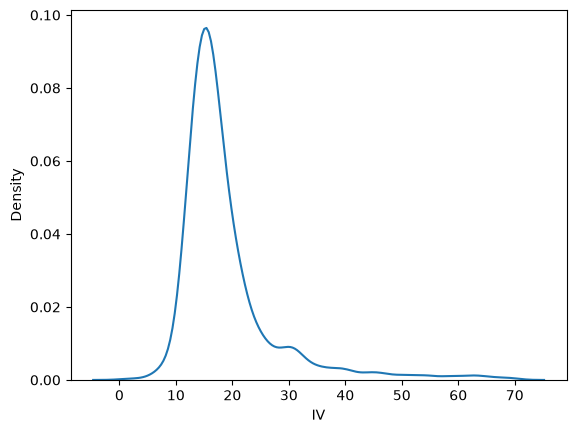

In [80]:
sb.kdeplot(oc["IV"])

<Axes: ylabel='IV'>

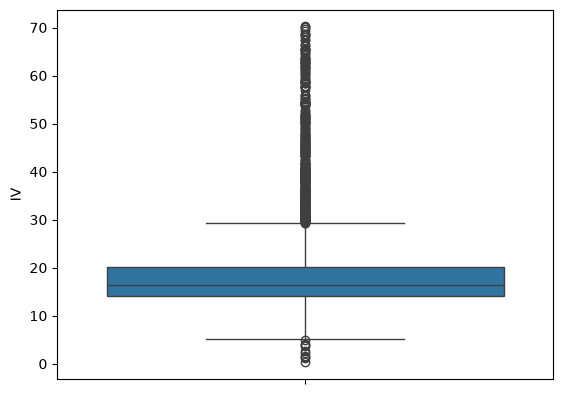

In [81]:
sb.boxplot(oc["IV"])

<h3>Using Quantiles</h3>

In [82]:
print(oc["IV"].max(),
oc["IV"].min(),
oc["IV"].mean(),
oc["IV"].std())

70.25 0.3 19.01706457526991 9.021221534743397


In [83]:
max = oc["IV"].quantile(0.98)
min = oc["IV"].quantile(0.02)
print(max, min)

51.152 10.113199999999999


In [84]:
oc[(oc["IV"]<max) & (oc["IV"]> min)]

,OPTION TYPE,STRIKE,LTP,UNDERLYING VALUE,IV,TIME TO MATURITY
0,Call,55500.0,760.00,55540.05,12.30,385
1,Call,57000.0,200.50,55540.05,12.28,385
2,Put,55500.0,739.05,55540.05,16.43,385
3,Call,58000.0,60.90,55540.05,12.25,385
4,Call,56000.0,515.00,55540.05,12.29,385
...,...,...,...,...,...,...
8675,Call,52100.0,4052.05,55488.10,19.07,400
8677,Call,53100.0,2659.25,55488.10,28.29,373
8678,Call,49000.0,6650.00,55488.10,47.87,373
8679,Put,51800.0,119.60,55488.10,18.48,400


<h3>Adding a missing Indicator Column<h>

In [90]:
from sklearn.impute import KNNImputer, MissingIndicator
from sklearn.model_selection import train_test_split

In [91]:
oc

,OPTION TYPE,STRIKE,LTP,UNDERLYING VALUE,IV,TIME TO MATURITY
0,Call,55500.0,760.00,55540.05,12.30,385
1,Call,57000.0,200.50,55540.05,12.28,385
2,Put,55500.0,739.05,55540.05,16.43,385
3,Call,58000.0,60.90,55540.05,12.25,385
4,Call,56000.0,515.00,55540.05,12.29,385
...,...,...,...,...,...,...
8676,Call,51500.0,4470.00,55488.10,NaN,400
8677,Call,53100.0,2659.25,55488.10,28.29,373
8678,Call,49000.0,6650.00,55488.10,47.87,373
8679,Put,51800.0,119.60,55488.10,18.48,400


In [92]:
x_train, x_test, y_train, y_test = train_test_split(oc.drop("LTP", axis = 1), oc["LTP"], test_size = 0.2)